In [75]:
import pandas as pd
import numpy as np
data = pd.read_csv("COVID-19_Vaccinations_by_Age_(Maricopa_County).csv")
data.info()
print(data.describe())
data.head(20)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4522 entries, 0 to 4521
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   OBJECTID             4522 non-null   int64  
 1   PostalCode           4522 non-null   int64  
 2   TotalVaccinated      4454 non-null   float64
 3   VaccinatedAge75Up    4454 non-null   float64
 4   VaccinatedAge65To74  4420 non-null   float64
 5   VaccinatedAge55To64  4454 non-null   float64
 6   VaccinatedAge45To54  4454 non-null   float64
 7   VaccinatedAge35To44  4427 non-null   float64
 8   VaccinatedAge25To34  4420 non-null   float64
 9   VaccinatedAge15To24  4452 non-null   float64
 10  VaccinatedAge0To14   4327 non-null   float64
 11  StartDate            4389 non-null   object 
 12  CreateDate           4389 non-null   object 
dtypes: float64(9), int64(2), object(2)
memory usage: 459.4+ KB
          OBJECTID    PostalCode  TotalVaccinated  VaccinatedAge75Up  \
count  

,OBJECTID,PostalCode,TotalVaccinated,VaccinatedAge75Up,VaccinatedAge65To74,VaccinatedAge55To64,VaccinatedAge45To54,VaccinatedAge35To44,VaccinatedAge25To34,VaccinatedAge15To24,VaccinatedAge0To14,StartDate,CreateDate
0,1,85190,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021/06/16 07:00:00+00,NaN
1,2,85333,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2021/06/16 07:00:00+00,NaN
2,3,85139,3.0,0.0,NaN,0.0,0.0,0.0,NaN,0.0,0.0,2021/06/16 07:00:00+00,NaN
3,4,85343,102.0,17.0,17.0,16.0,17.0,16.0,12.0,NaN,0.0,2021/06/16 07:00:00+00,NaN
4,5,85377,2662.0,817.0,936.0,528.0,146.0,72.0,82.0,72.0,NaN,2021/06/16 07:00:00+00,NaN
5,6,85263,3164.0,978.0,1300.0,709.0,77.0,27.0,36.0,31.0,NaN,2021/06/16 07:00:00+00,NaN
6,7,85322,229.0,34.0,43.0,54.0,25.0,25.0,30.0,15.0,NaN,2021/06/16 07:00:00+00,NaN
7,8,85320,509.0,56.0,60.0,80.0,53.0,67.0,143.0,50.0,0.0,2021/06/16 07:00:00+00,NaN
8,9,85264,700.0,44.0,109.0,148.0,106.0,123.0,89.0,71.0,10.0,2021/06/16 07:00:00+00,NaN
9,10,85342,491.0,114.0,158.0,80.0,50.0,36.0,26.0,25.0,NaN,2021/06/16 07:00:00+00,NaN


Preprocessing and cleanup

In [76]:
data.dropna(inplace=True)
# data.info()
f2icols = ['TotalVaccinated', 'VaccinatedAge75Up', 'VaccinatedAge65To74', 'VaccinatedAge55To64', 'VaccinatedAge45To54', 'VaccinatedAge35To44', 'VaccinatedAge25To34', 'VaccinatedAge15To24', 'VaccinatedAge0To14']
data[f2icols] = data[f2icols].map(np.int64)
data['StartDate'] = pd.to_datetime(data['StartDate'], format='%Y/%m/%d %H:%M:%S%z')
data['YearMonth'] = data['StartDate'].dt.strftime('%Y-%m')
data.info()
print(data.describe())
#data.sort_values('StartDate').head(20)
data.sort_values('StartDate').tail(20)

<class 'pandas.core.frame.DataFrame'>
Index: 4041 entries, 140 to 4521
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype              
---  ------               --------------  -----              
 0   OBJECTID             4041 non-null   int64              
 1   PostalCode           4041 non-null   int64              
 2   TotalVaccinated      4041 non-null   int64              
 3   VaccinatedAge75Up    4041 non-null   int64              
 4   VaccinatedAge65To74  4041 non-null   int64              
 5   VaccinatedAge55To64  4041 non-null   int64              
 6   VaccinatedAge45To54  4041 non-null   int64              
 7   VaccinatedAge35To44  4041 non-null   int64              
 8   VaccinatedAge25To34  4041 non-null   int64              
 9   VaccinatedAge15To24  4041 non-null   int64              
 10  VaccinatedAge0To14   4041 non-null   int64              
 11  StartDate            4041 non-null   datetime64[ns, UTC]
 12  CreateDate           40

,OBJECTID,PostalCode,TotalVaccinated,VaccinatedAge75Up,VaccinatedAge65To74,VaccinatedAge55To64,VaccinatedAge45To54,VaccinatedAge35To44,VaccinatedAge25To34,VaccinatedAge15To24,VaccinatedAge0To14,StartDate,CreateDate,YearMonth
4443,4711,85086,22993,3117,4077,4190,3768,2454,1535,2796,1056,2022-02-16 16:23:35+00:00,2022/02/16 16:23:35+00,2022-02
4442,4710,85374,29343,10248,6996,3529,2357,1889,1841,1915,568,2022-02-16 16:23:35+00:00,2022/02/16 16:23:35+00,2022-02
4441,4709,85298,25015,2525,3404,3295,4752,4067,1657,3261,2054,2022-02-16 16:23:35+00:00,2022/02/16 16:23:35+00,2022-02
4440,4708,85396,19772,2323,4847,3285,2490,2374,1702,1868,883,2022-02-16 16:23:35+00:00,2022/02/16 16:23:35+00,2022-02
4439,4707,85013,15293,959,1673,2155,2254,2785,3369,1488,610,2022-02-16 16:23:35+00:00,2022/02/16 16:23:35+00,2022-02
4438,4706,85381,15941,2179,2466,2754,2093,1939,1996,1827,687,2022-02-16 16:23:35+00:00,2022/02/16 16:23:35+00,2022-02
4437,4705,85085,17442,979,1805,2420,3039,3400,2620,1903,1276,2022-02-16 16:23:35+00:00,2022/02/16 16:23:35+00,2022-02
4436,4704,85050,23438,2552,2644,3310,4043,3938,2492,2630,1829,2022-02-16 16:23:35+00:00,2022/02/16 16:23:35+00,2022-02
4435,4703,85255,35890,6136,6465,7058,5380,3146,2606,3564,1535,2022-02-16 16:23:35+00:00,2022/02/16 16:23:35+00,2022-02
4434,4702,85249,33028,3816,4047,4632,6591,4300,2075,4825,2742,2022-02-16 16:23:35+00:00,2022/02/16 16:23:35+00,2022-02


In [77]:
df_grouped = data.groupby('YearMonth').agg({
    'TotalVaccinated': 'sum',
    'VaccinatedAge75Up': 'sum',
    'VaccinatedAge65To74': 'sum',
    'VaccinatedAge55To64': 'sum',
    'VaccinatedAge45To54': 'sum',
    'VaccinatedAge35To44': 'sum',
    'VaccinatedAge25To34': 'sum',
    'VaccinatedAge15To24': 'sum',
    'VaccinatedAge0To14': 'sum'
}).reset_index()
#print(df_grouped.info())
df_grouped.head(100)

,YearMonth,TotalVaccinated,VaccinatedAge75Up,VaccinatedAge65To74,VaccinatedAge55To64,VaccinatedAge45To54,VaccinatedAge35To44,VaccinatedAge25To34,VaccinatedAge15To24,VaccinatedAge0To14
0,2021-06,3959242,461737,626001,675144,601486,559697,524968,433070,77139
1,2021-07,8163674,938803,1270645,1377071,1241558,1157015,1087488,915981,175113
2,2021-08,8288572,931144,1245817,1361144,1256895,1186686,1123246,974782,208858
3,2021-09,16379895,1803034,2376071,2614676,2456935,2356530,2266208,2023359,483082
4,2021-10,7129400,783188,1026034,1130325,1068044,1028943,994683,887427,210756
5,2021-11,7237192,793535,1030569,1141019,1084544,1048359,1017349,908847,212970
6,2021-12,7313339,802748,1033654,1148259,1094124,1059008,1030099,921394,224053
7,2022-01,10305550,1105523,1409473,1567704,1499150,1456789,1436723,1298043,532145
8,2022-02,5270626,561496,712892,794854,762450,742070,734966,671078,290820


 How do the vaccination totals between age groups compare? 

/var/folders/p9/frtk4fwx3nzdw7xqnvjwz2sw0000gn/T/ipykernel_38460/1833846207.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=melted, x='AgeGroup', y='Count', inner='quartile', palette='pastel')


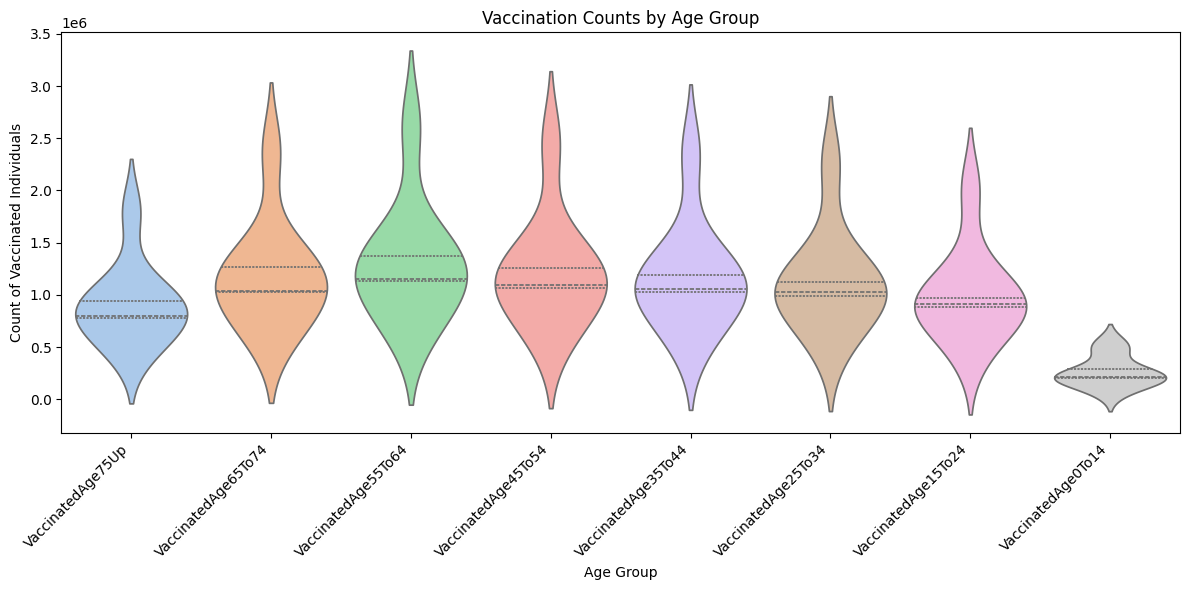

In [81]:
import matplotlib.pyplot as plt
import seaborn as sns
# Melt the DataFrame to long format
melted = df_grouped[['YearMonth', 'VaccinatedAge75Up', 'VaccinatedAge65To74', 'VaccinatedAge55To64', 'VaccinatedAge45To54', 'VaccinatedAge35To44', 'VaccinatedAge25To34', 'VaccinatedAge15To24', 'VaccinatedAge0To14']].melt(id_vars='YearMonth', var_name='AgeGroup', value_name='Count')

# Create a violin plot
plt.figure(figsize=(12, 6))
sns.violinplot(data=melted, x='AgeGroup', y='Count', inner='quartile', palette='pastel')
plt.title('Vaccination Counts by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Count of Vaccinated Individuals')
#plt.yticks(np.arange(0, 3500000))
plt.xticks(rotation=45, ha='right')
plt.tight_layout()  # Adjust layout to fit labels
plt.show()

/var/folders/p9/frtk4fwx3nzdw7xqnvjwz2sw0000gn/T/ipykernel_38460/1597015338.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=melted, x='AgeGroup', y='Count', inner='quartile', palette='pastel')


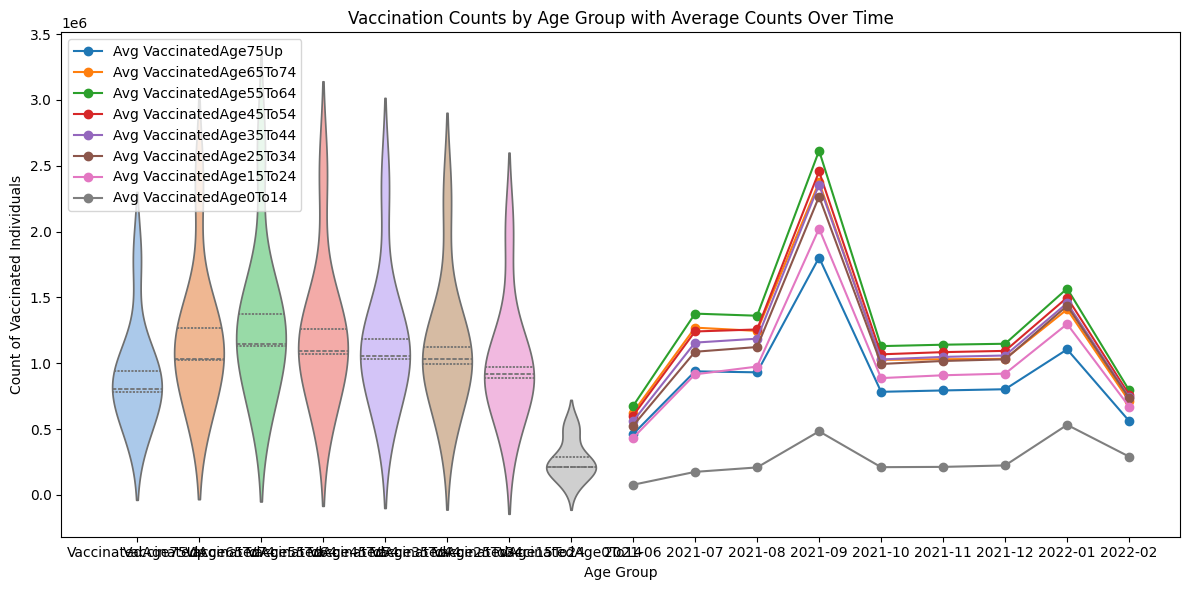

In [123]:
#drop the total column
df = df_grouped[['YearMonth', 'VaccinatedAge75Up', 'VaccinatedAge65To74', 'VaccinatedAge55To64', 'VaccinatedAge45To54', 'VaccinatedAge35To44', 'VaccinatedAge25To34', 'VaccinatedAge15To24', 'VaccinatedAge0To14']]
# Melt the DataFrame to long format
melted = df.melt(id_vars='YearMonth', var_name='AgeGroup', value_name='Count')

# Calculate average counts for each age group over months
average_counts = df.drop(columns='YearMonth').mean().reset_index()
average_counts.columns = ['AgeGroup', 'AverageCount']

# Create a violin plot
plt.figure(figsize=(12, 6))
sns.violinplot(data=melted, x='AgeGroup', y='Count', inner='quartile', palette='pastel')

# Overlay average counts as a line plot
for age_group in average_counts['AgeGroup']:
    # Extract the average counts for the current age group
    avg_values = df_grouped[age_group].values
    plt.plot(df_grouped['YearMonth'], avg_values, marker='o', label=f'Avg {age_group}')

# Customize the plot
plt.title('Vaccination Counts by Age Group with Average Counts Over Time')
plt.xlabel('Age Group')
plt.ylabel('Count of Vaccinated Individuals')
plt.legend(loc='upper left')
plt.tight_layout() 

# Show the plot
plt.show()

/var/folders/p9/frtk4fwx3nzdw7xqnvjwz2sw0000gn/T/ipykernel_38460/145092961.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=melted, x='AgeGroup', y='Count', inner='quartile', palette='pastel')


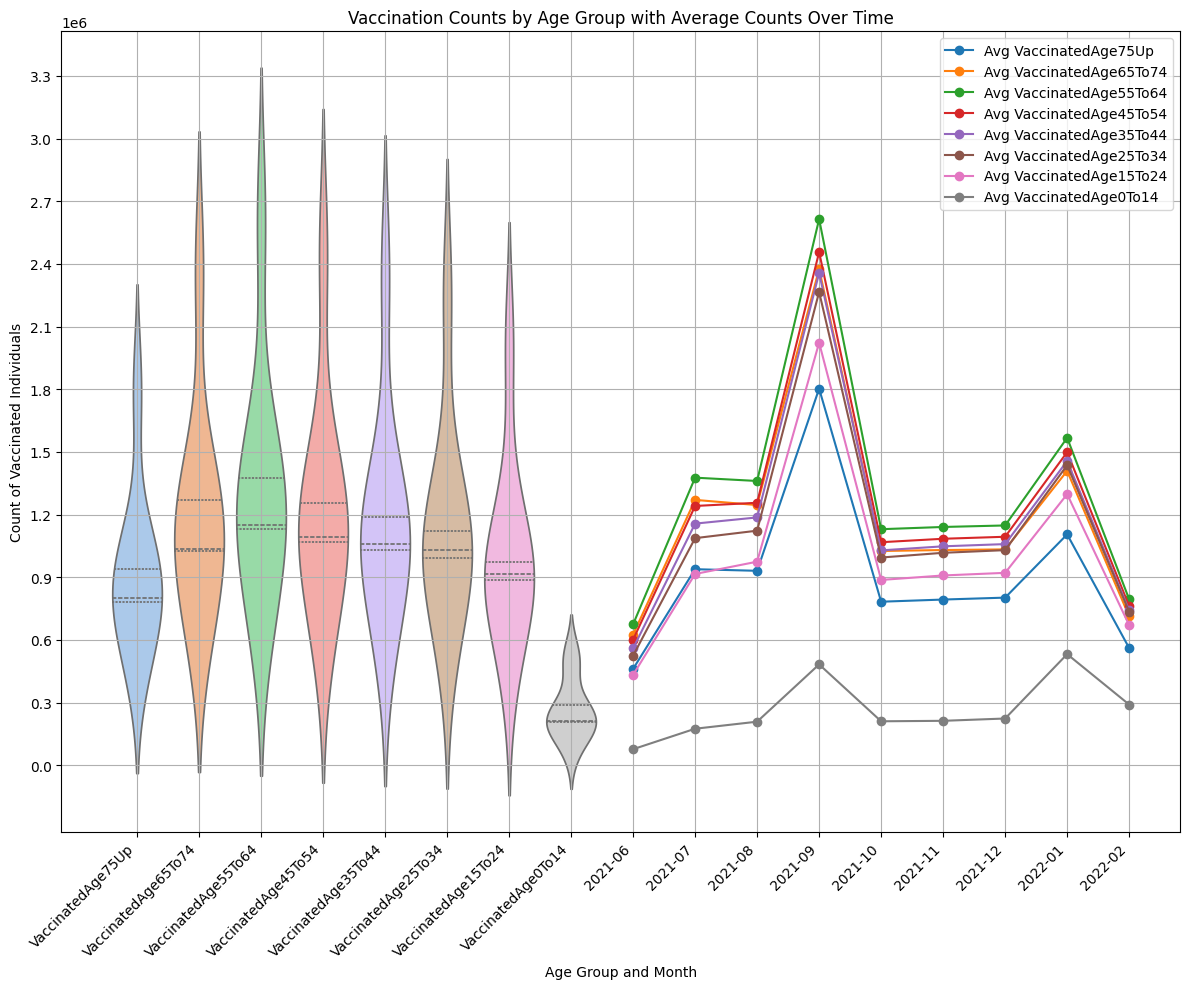

In [124]:
#drop the total column
df = df_grouped[['YearMonth', 'VaccinatedAge75Up', 'VaccinatedAge65To74', 'VaccinatedAge55To64', 'VaccinatedAge45To54', 'VaccinatedAge35To44', 'VaccinatedAge25To34', 'VaccinatedAge15To24', 'VaccinatedAge0To14']]
# Melt the DataFrame to long format
melted = df.melt(id_vars='YearMonth', var_name='AgeGroup', value_name='Count')

# Calculate average counts for each age group over months
average_counts = df.drop(columns='YearMonth').mean().reset_index()
average_counts.columns = ['AgeGroup', 'AverageCount']

# Create a figure and axes
plt.figure(figsize=(12, 10))

# Create the violin plot
sns.violinplot(data=melted, x='AgeGroup', y='Count', inner='quartile', palette='pastel')

# Overlay average counts as a line plot
for age_group in average_counts['AgeGroup']:
    # Extract the average counts for the current age group
    avg_values = df_grouped[age_group].values
    plt.plot(df_grouped['YearMonth'], avg_values, marker='o', label=f'Avg {age_group}')

# Customize the plot
plt.title('Vaccination Counts by Age Group with Average Counts Over Time')
plt.xlabel('Age Group and Month')
plt.ylabel('Count of Vaccinated Individuals')
plt.xticks(rotation=45, ha='right')

# Add grid lines
plt.grid(True)

# Increase granularity of the y-axis
plt.yticks(range(0, 3500000, 300000))  

# Add legend in the upper left corner
plt.legend(loc='upper right')

# Adjust layout to fit labels
plt.tight_layout()

# Show the plot
plt.show()
